___


--- 


## This main code is part of the paper "Analysis of Socioeconomic Indicators in Brazil and the Americas," by L.C. Rossato, S. Gonçalves, and J.R. Iglesias.

--- 

 For better visualization, use Jupyter.

---

#### 7 References Databases: Goverment Data Sites (or oficial pdf informes HDI):
* `Mexico`:  [Link Database Mexico](https://www.inegi.org.mx/siscon/)
* `Chile`:   [Link Database Chile](https://repositorio.uautonoma.cl/bitstream/handle/20.500.12728/6742/V11digitalfinal.pdf?sequence=1&isAllowed=y)
* `Peru`: [Link Database Peru](https://www.up.edu.pe/egp/programas-especializacion_copy(1)/SiteAssets/Lists/Observatorio/AllItems/Informe%20de%20Evidencia%20IDH%202019.pdf)
* `El Salvador`:  [Link Database El_Salvador](https://www.undp.org/sites/g/files/zskgke326/files/publications/El%20Salvador_MDGReport_2005_SP.pdf)
* `Brazil`:  [Link Database Brazil](https://censo2010.ibge.gov.br/resultados.html)
* `USA`:  [Link Database USA](https://web.archive.org/web/20110615084942/http://www.census.gov/hhes/www/poverty/poverty.html)
____

#### Used colors in paper for Brazil macrorregions:  
HEX Colors = ['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728', '#9467BD'] ; Respectively [Midwest, Southeast, North, Northeast  and South]

#### List of colors for different datasets:
['green', 'blue', 'red', 'purple', 'orange', 'brown'] <=> [Brazil, Chile, Peru, Mexico , El Salvador and USA]


___
___
___


# Base on GCA (Gravitional Cluster Algorithmn)

### The monochromatic graphs found in Fig. 5 and Fig. 8 are based on this notebook.

Fig. 5: Process of transforming a scatter plot into a graph using an original variation
of the ”Gravitational Clustering Algorithm” (GCA). The metric plane is based on the
monitor’s DPI rate, and the formulation of the Cut Radius is arbitrary.

Fig. 8: Comparison between the scatter plot and the respective numerical series after
the graph conversion process using ”Based on GCA” (Sec. 2.3). The countries analyzed
include: Brazil, Chile, Peru, Mexico, El Salvador, and the USA.

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
import networkx as nx
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Import dataframes
df_ElSalvador = pd.read_csv('df_ElSalvador.csv')
df_Chile      = pd.read_csv('df_Chile.csv')
df_Mexico     = pd.read_csv('df_Mexico.csv')
df_Peru       = pd.read_csv('df_Peru.csv')
df_USA        = pd.read_csv('df_USA.csv')
df_Brazil     = pd.read_csv('df_Brazil.csv')

def plot_with_plotly(axis_x, axis_y, df, width_pixels, height_pixels, hover_texts, file_name):
    # Data preparation
    log_x = np.log(df[axis_x])
    log_y = np.log(df[axis_y])

    # Fitting a log-log trendline
    model = sm.OLS(log_y, sm.add_constant(log_x)).fit()
    predicted = model.predict(sm.add_constant(log_x))

    # Converting predictions to original (non-logarithmic) values
    exp_predicted = np.exp(predicted)

    # Updating hover_texts to include the index value
    hover_texts_with_index = [f"Index: {idx}<br>{text}" for idx, text in zip(df['original_index'], hover_texts)]
    
    # Plotting the graph with plotly
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=df[axis_x], y=df[axis_y], mode='markers', name='Data Points', hovertext=hover_texts_with_index))
    fig.add_trace(go.Scatter(x=df[axis_x], y=exp_predicted, mode='lines', name="OLS Fit"))

    fig.update_layout(title=f"Scatter plot of {axis_x} vs. {axis_y} with OLS Fit",
                      xaxis_type="log", yaxis_type="log", template="simple_white",
                      xaxis_title=axis_x, yaxis_title=axis_y,
                      width=width_pixels, height=height_pixels)
#     fig.write_image(file_name+'scatter.png')
#     fig.write_image(file_name+'scatter.svg')
    fig.show()

def plot_with_matplotlib(axis_x, axis_y, df, width_pixels, height_pixels, hover_names):
    # Convert pixels to inches (assuming a standard resolution of 100 dpi)
    width_inches = width_pixels / 100.0
    height_inches = height_pixels / 100.0
    
    # Data preparation
    log_x = np.log(df[axis_x])
    log_y = np.log(df[axis_y])
    
    # Fitting a log-log trendline
    model = sm.OLS(log_y, sm.add_constant(log_x)).fit()
    predicted = model.predict(sm.add_constant(log_x))

    # Plotting the graph
    fig, ax = plt.subplots(figsize=(width_inches, height_inches))
    ax.scatter(df[axis_x], df[axis_y], c='blue', alpha=0.5, label='Data Points')
    ax.plot(df[axis_x], np.exp(predicted), color='black', label="OLS Fit")
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(axis_x)
    ax.set_ylabel(axis_y)
    ax.set_title(f"Scatter plot of {axis_x} vs. {axis_y} with OLS Fit")
    ax.legend()

    pixel_positions = []
    for i in range(len(df)):
        x, y = df[axis_x].iloc[i], df[axis_y].iloc[i]
        pixel_coords = ax.transData.transform((x, y))
        pixel_positions.append(pixel_coords)
    
    # Now, generate hover_texts
    hover_texts = [f"Index: {idx}<br>{name}<br>Pixel: ({int(pixel[0])}, {int(pixel[1])})"
                   for idx, name, pixel in zip(df['original_index'], hover_names, pixel_positions)]

    plt.close(fig)  # close the figure without showing it
    return pixel_positions

def calculate_graph_and_metrics(Cut_Rad, axis_x, axis_y, index, hover_names, title, color_scale, file_name):
    df = pd.DataFrame({'x': axis_x, 'y': axis_y, 'original_index': index})
    
    # Calculating pixel positions using matplotlib to obtain positions
    pixel_positions = plot_with_matplotlib('x', 'y', df, 800, 500, hover_names)
    hover_texts = [f"{name}<br>Pixel: ({int(pixel[0])}, {int(pixel[1])})" for name, 
                   pixel in zip(hover_names, pixel_positions)]
    
    # Plotting using plotly
#     plot_with_plotly('x', 'y', df, 800, 500, hover_texts, file_name)
    
    # Base on Gravitional Clustering Algorithm
    def gravity_cluster(Cut_Rad, pixel_positions, index):
        Cut_Rad_Pixel_x_Pixel = []
        for i in range(len(pixel_positions)):
            for j in range(i + 1, len(pixel_positions)):
                pitagoras = np.sqrt((pixel_positions[j][0] - pixel_positions[i][0]) ** 2 + 
                                    (pixel_positions[j][1] - pixel_positions[i][1]) ** 2)               
                if pitagoras <= Cut_Rad:
                    Cut_Rad_Pixel_x_Pixel.append([index[i], index[j]])                    
        return Cut_Rad_Pixel_x_Pixel

    def create_gravity_clustering_graph(Cut_Rad):
        G = nx.Graph()
        for i in range(len(axis_x)):
            G.add_node(i)
        for i in Cut_Rad:
            G.add_edge(i[0], i[1])
        return G

    def print_graph(G, title, hover_names):
        pos = nx.spring_layout(G)  # Arbitrary layout 
        edge_x, edge_y = [], []
        for edge in G.edges():
            x0, y0 = pos[edge[0]]
            x1, y1 = pos[edge[1]]
            edge_x.extend([x0, x1, None])
            edge_y.extend([y0, y1, None])

        edge_trace = go.Scatter(x=edge_x, y=edge_y, line=dict(width=1, color="#000000"),
                                hoverinfo="none", mode="lines")
        node_x, node_y = [], []
        for node in G.nodes():
            x, y = pos[node]
            node_x.append(x)
            node_y.append(y)
        
        node_degree = list(dict(G.degree()).values())  # <-- This line calculates the degree of each node
        
        node_trace = go.Scatter(x=node_x, y=node_y, mode="markers", hoverinfo="text", 
                                text=[f"Index: {idx}<br>{text}" for idx, text in zip(df['original_index'], hover_texts)],
                                marker=dict(showscale=True, colorscale=color_scale, size=8, line_width=0.5, color=node_degree,
                                            colorbar=dict(thickness=25, title="Node Degree", xanchor="left", titleside="right")
                                            )
                               )       
        fig = go.Figure(data=[edge_trace, node_trace],
                        layout=go.Layout(title=title, titlefont_size=16, showlegend=False,
                            plot_bgcolor="white", paper_bgcolor="white", width=800, height=400,
                            hovermode="closest", margin=dict(b=0, l=0, r=0, t=40),
                            annotations=[dict(text="", showarrow=False, xref="paper", yref="paper")],
                            xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                            yaxis=dict(showgrid=False, zeroline=False, showticklabels=False))
                       )
#         fig.write_image(file_name+'graph.png')
#         fig.write_image(file_name+'graph.svg')
        fig.show()
      
    def get_degree_for_all_nodes(G, total_nodes):
        # Get the degree of all nodes in the graph
        degree_dict = dict(G.degree())

        # Fill in missing degrees with 0
        degrees = [degree_dict.get(i, 0) for i in range(total_nodes)]

        return degrees

    Cut_Rad = gravity_cluster(Cut_Rad, pixel_positions, df['original_index'].values)
    G = create_gravity_clustering_graph(Cut_Rad)
    degrees = get_degree_for_all_nodes(G, len(axis_x))
    print_graph(G, title, hover_texts)
    return G, degrees

color_scale = 'brwnyl_r'

# Modifications in histogram functions to add the curve that follows the tops of the bins
def degree_histogram_by_population(degrees, axis_x, file_name):
    bins = np.logspace(np.log10(min(axis_x)), np.log10(max(axis_x)), num=11)
    labels = list(range(len(bins)-1))

    df_bins = pd.DataFrame({'Population': axis_x, 'Degree': degrees})
    df_bins['Bin'] = pd.cut(df_bins['Population'], bins=bins, labels=labels, include_lowest=True)

    df_bins = df_bins.groupby('Bin').Degree.mean().reset_index()
    df_bins['Population'] = ['{:.2f} to {:.2f}'.format(bins[i], bins[i+1]) for i in labels]

    fig = px.bar(df_bins, x='Population', y='Degree', title='Average Degree by Bin Distribution',
                 color='Degree', color_continuous_scale=color_scale)
    
    # Add the curve that follows the tops of the bins
    fig.add_trace(go.Scatter(x=df_bins['Population'], y=df_bins['Degree'],
                             mode='lines', 
                             line=dict(color='brown'),
                             name='Top curve'))

    fig.update_layout(template="simple_white", width=500, height=500, 
                      legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
                      coloraxis_colorbar=dict(yanchor="top", y=1, ypad=10)
                     )
    fig.update_traces(marker_line_width=1, marker_line_color='black')
#     fig.write_image(file_name+'histogram.png')
#     fig.write_image(file_name+'histogram.svg')    
    fig.show()

def graph_info(G, degrees):
    # Calculate various graph metrics
    num_nodes = G.number_of_nodes()  # Number of nodes in the graph
    num_edges = G.number_of_edges()  # Number of edges in the graph
    density = num_edges / num_nodes  # Density of the graph (edges per node)
    avg_degree = np.mean(degrees)    # Average degree of nodes
    variance = np.var(degrees)       # Variance of node degrees
    std_dev = np.std(degrees)        # Standard deviation of node degrees
    q25, q50, q75 = np.percentile(degrees, [25, 50, 75])  # Quartiles of node degrees

    max_degree = np.max(degrees)     # Maximum degree of nodes
    min_degree = np.min(degrees)     # Minimum degree of nodes

    node_max_degree = np.argmax(degrees)  # Index of the node with the maximum degree
    node_min_degree = np.argmin(degrees)  # Index of the node with the minimum degree

    # Create a DataFrame to store graph metrics
    df_info = pd.DataFrame({
        'Metric': [
            'Number of nodes', 'Number of edges', 'Density (edges / nodes)',
            'Average degree', 'Max degree', 'Min degree', 
            'Variance', 'Standard deviation', 
            '1st Quartile', 'Median', '3rd Quartile'
        ],
        'Value': [
            num_nodes, num_edges, density,
            avg_degree, max_degree, min_degree,
            variance, std_dev,
            q25, q50, q75
        ]
    })
    display(df_info.round(2))  # Display the DataFrame with rounded values



def styled_graph_info(G, degrees, png_path='styled_table.png', svg_path='styled_table.svg'):
    # Calculate various graph metrics
    num_nodes = G.number_of_nodes()  # Number of nodes in the graph
    num_edges = G.number_of_edges()  # Number of edges in the graph
    avg_degree = np.mean(degrees)    # Average degree of nodes
    variance = np.var(degrees)       # Variance of node degrees
    std_dev = np.std(degrees)        # Standard deviation of node degrees
    q25, q50, q75 = np.percentile(degrees, [25, 50, 75])  # Quartiles of node degrees

    # Calculate eccentricity only for the largest connected component
    largest_cc = max(nx.connected_components(G), key=len)
    subgraph = G.subgraph(largest_cc)
    ecc = nx.eccentricity(subgraph)
    avg_eccentricity = np.mean(list(ecc.values()))  # Average eccentricity of nodes

    max_degree = np.max(degrees)  # Maximum degree of nodes
    min_degree = np.min(degrees)  # Minimum degree of nodes

    # Create a DataFrame to store graph metrics
    df_info = pd.DataFrame({
        'Metric': [
            'Nº of nodes', 'Nº of edges',
            'Average degree', 'Max. degree', 'Min. degree', 
            'Variance', 'Standard deviation', 'Average eccentricity'
        ],
        'Value': [
            num_nodes, num_edges, 
            avg_degree, max_degree, min_degree,
            variance, std_dev, avg_eccentricity
        ]
    })    
    
    fig, ax = plt.subplots(figsize=(12, 7))  # Increasing figure size
    ax.axis('off')
    ax.set_frame_on(False)
    
    colors = ['#d1afa1' if i % 2 == 0 else '#f5ece9' for i in range(len(df_info.round(1)))]
    
    the_table = ax.table(cellText=df_info.round(1).values, colLabels=df_info.columns, 
                         cellLoc = 'center', loc='center', cellColours=[[c]*2 for c in colors])
    the_table.auto_set_font_size(False)
    the_table.set_fontsize(12)
    the_table.auto_set_column_width(col=list(range(len(df_info.columns))))
    
    for (i, j), cell in the_table.get_celld().items():
        cell.set_edgecolor((0.5, 0.16, 0.16, 0.5))  # Brown with opacity 0.5
        if i == 0:  # Header
            cell.set_text_props(fontweight='bold')
            cell.set_facecolor('#a68e85')  # Yellow background
            cell.set_height(0.08)  # Larger height
        else:
            cell.set_edgecolor('#a68e85')  # Removing borders from other cells
            cell.set_height(0.05)
    
    plt.tight_layout()
    
#     plt.savefig(png_path, bbox_inches='tight', dpi=300)
#     plt.savefig(svg_path, bbox_inches='tight')
    plt.show()


# df_ElSalvador

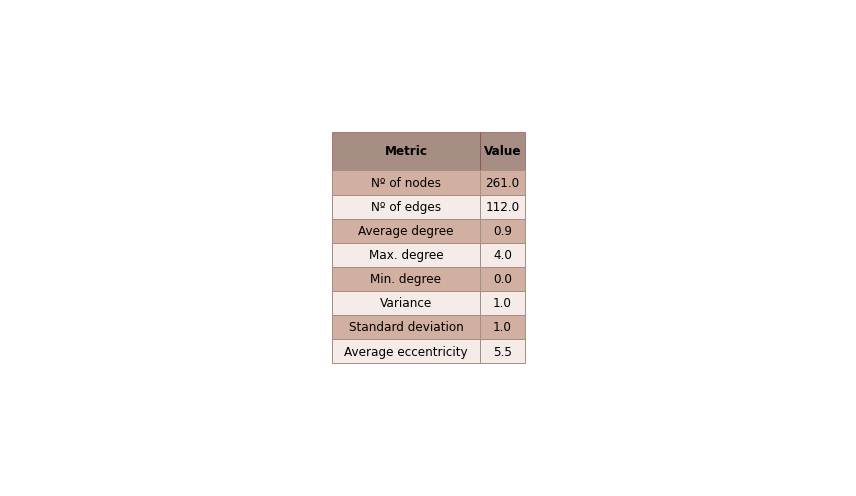

In [8]:
df_ElSalvador = df_ElSalvador[~df_ElSalvador.IDH_2005.isna()]
df = df_ElSalvador.sort_values('Pop_total_2005').reset_index(drop=True)

axis_y = list(df.IDH_2005)
axis_x = list(df.Pop_total_2005)
index = df.index
Cut_Rad = 5
title = 'GCA: df_ElSalvador | Cut_Rad: '+str(Cut_Rad)
hovername = df_ElSalvador.Comuna
file_name = 'df_ElSalvador'

G_ElSalvador, degrees_ElSalvador = calculate_graph_and_metrics(Cut_Rad, axis_x, axis_y, index, hovername, title, color_scale, file_name)
styled_graph_info(G_ElSalvador, degrees_ElSalvador)

# df_Peru

In [ ]:
df = df_Peru.sort_values('Pop_2017')
axis_y = list(df.HDI_2017)
axis_x = list(df.Pop_2017)
index = df.index
Cut_Rad = 5
title = 'GCA: df_Peru | Cut_Rad: '+str(Cut_Rad)
hovername = df_Peru.City
file_name = 'df_Peru_CutRad_5'

G_Peru, degrees_Peru = calculate_graph_and_metrics(Cut_Rad, axis_x, axis_y, index, hovername, title, color_scale, file_name)
styled_graph_info(G_Peru, degrees_Peru)

# df_Mexico

In [ ]:
df = df_Mexico.sort_values('Pop_Total_2010')
axis_y = list(df.IDH_2000)
axis_x = list(df.Pop_Total_2010)
index = df.index
Cut_Rad = 5
title = 'GCA: df_Mexico | Cut_Rad: '+str(Cut_Rad)
hovername = df.Hovername
file_name = 'df_Mexico_CutRad_5'

G_Mexico, degrees_Mexico = calculate_graph_and_metrics(Cut_Rad, axis_x, axis_y, index, hovername, title, color_scale, file_name)
styled_graph_info(G_Mexico, degrees_Mexico)


# df_Chile

In [ ]:
df = df_Chile.sort_values('Población_2017')
axis_y = list(df.IDC_2020)
axis_x = list(df.Población_2017)
index = df.index
Cut_Rad = 5
title = 'GCA: df_Chile | Cut_Rad: '+str(Cut_Rad)
hovername = df_Chile.COMUNA
file_name = 'df_Chile_CutRad_5'
G_Chile, degrees_Chile = calculate_graph_and_metrics(Cut_Rad, axis_x, axis_y, index, hovername, title, color_scale, file_name)
styled_graph_info(G_Chile, degrees_Chile)


# df_USA: per County

In [ ]:
# Use groupby to group by 'County' and perform the desired operations
df_aggregated = df_USA.groupby(['County']).agg({
    '2015_Tract_population': 'sum',
    'adjusted_hdi': 'mean',
    'unadjusted_hdi': 'mean',
    'unadjusted_income_index': 'mean',    
    'adjusted_income_index': 'mean',
    'expect_edu_index': 'mean',
    'mean_edu_index': 'mean',
    'final_edu_index': 'mean',
    'le_index': 'mean',
    'Macroregion': 'first',
}).reset_index()
df_USA_PerCounty = df_aggregated[df_aggregated['unadjusted_hdi'].notna()]

df = df_USA_PerCounty.sort_values('2015_Tract_population')
axis_y = list(df.unadjusted_income_index)
axis_x = list(df['2015_Tract_population'])
index = df.index
Cut_Rad = 5
title = 'GCA: df_USA_PerCounty | Cut_Rad: '+str(Cut_Rad)
hovername = df_USA_PerCounty.County
file_name = 'df_USA_perCounty_CutRad_5'

G_USA, degrees_USA = calculate_graph_and_metrics(Cut_Rad, axis_x, axis_y, index, hovername, title, color_scale, file_name)
styled_graph_info(G_USA, degrees_USA)


# df_Brazil

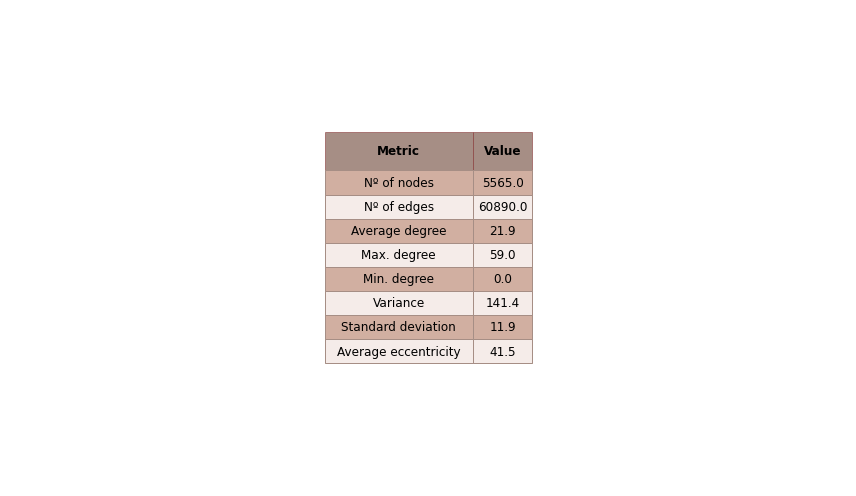

In [5]:
df = df_Brazil.sort_values('Total_Pop_Absol')
axis_y = list(df.IDHM_2010)
axis_x = list(df.Total_Pop_Absol)
index = df.index
Cut_Rad = 5
title = 'GCA: df_Brazil | Cut_Rad: '+str(Cut_Rad)
hovername = df_Brazil.Municipio
file_name = 'df_Brazil_CutRad_5'

G_Brazil, degrees_Brazil = calculate_graph_and_metrics(Cut_Rad, axis_x, axis_y, index, hovername, title, color_scale, file_name)
styled_graph_info(G_Brazil, degrees_Brazil)
